# The multilayer perceptron
*Reading the Doors of Durin.*

Some problems resist code. Nobody can write the rule that tells one
scrawled letter from another, or a voice from noise; every attempt is a
thousand special cases and still wrong. The way round is to write a
function with parameters instead of a rule, collect examples of right answers,
and turn the parameters until the function gives them. The function then
answers new cases on its own.

The *multilayer perceptron* is the simplest such function that works at
scale: small identical parts, each with a few parameters, arranged in layers.
Every network in use today is built from it, from one that reads
handwriting to one that writes text. Below it is built up one part at a
time, each part tried on data until the data breaks it and the next part
is needed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import count, islice

MADDER, PRUSSIAN, VERDIGRIS = '#a4402c', '#1c4e73', '#2b6f68'
OCHRE, CONSTRUCT = '#b58a1e', '#c3c9cf'

## The doors

![The Doors of Durin](doors.png)

The west door of Moria is a smooth wall of rock with nothing to see on
it. Narvi the dwarf made it, and Celebrimbor the elf drew its signs in
*ithildin*, a silver alloy that stays invisible until starlight or
moonlight falls on it. Then a design appears: two trees, an arch, a crown
of seven stars, and round the arch a line of writing in Elvish letters.

1. How bright are the lines at a given hour? Before the doors were
   hung, the ithildin was tried for forty nights. An apprentice logged the
   hour after sunset, the haze over the mountains, and the glow of the
   lines, 0 for bare stone and 1 for full silver. Two numbers in, one out.
2. Is a given spot on the door silver or stone? On the night at the
   doors, clouds crossed the moon and lit the wall a patch at a time.
   Wherever a patch fell, the hobbits noted silver or stone at each spot.
   Two numbers in, a yes or no out.
3. Which letter is this? Elvish letters as pictures of 16 by 16
   pixels. 256 numbers in, one of twelve letters out.

## I. The perceptron

A perceptron takes a few numbers in. Each input is multiplied by its own
weight, the products are added together with a bias, and the sum is
passed through a fixed function $\sigma$.

![A perceptron](neuron.svg)

$$z = w \cdot x + b, \qquad y = \sigma(z), \qquad
\sigma(z) = \frac{1}{1 + e^{-z}}$$

The inputs are the vector $x$, the weights are the vector $w$, and $b$ is
the bias. The weights and the bias are the parameters of the perceptron.
The function $\sigma$ is called the activation function. It is chosen
once and is not changed by training. The usual first choice is the
sigmoid above, which turns any number into a number between 0 and 1.

In code, $x$ is a matrix with one row per case, so that many cases go
through at once.

In [2]:
def linear_perceptron(x, w, b):
    return x @ w + b

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def perceptron(x, w, b):
    return sigmoid(linear_perceptron(x, w, b))

x = np.array([[1.0, 2.0]])          # one case with two inputs
w, b = np.array([0.5, -1.0]), 0.2   # parameters, picked for the example
print(linear_perceptron(x, w, b), perceptron(x, w, b))   # predict: z, then y

[-1.3] [0.21416502]


### Problem I: how bright are the lines

The dataset is the apprentice's readings. Each reading has the hour after
sunset, the haze, and the glow of the lines. The hour divided by 12 is
called the time, so that it runs from 0 to 1 like the haze does. The time
and the haze are the two inputs. The glow is the right answer.

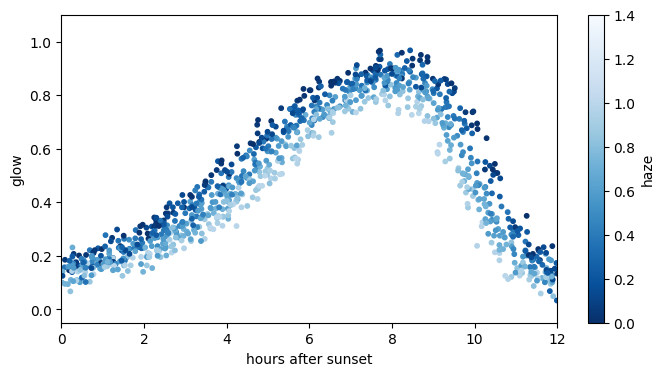

In [3]:
dataset = np.loadtxt('data/ithildin.csv', delimiter=',', skiprows=1)
night, hours, haze, glow = dataset.T
time = hours / 12
inputs = np.column_stack([time, haze])   # one row per reading

def draw_glow(rows=slice(None)):
    plt.figure(figsize=(8, 4))
    plt.scatter(hours[rows], glow[rows], c=haze[rows], cmap='Blues_r',
                vmin=0, vmax=1.4, s=10, label='readings')
    plt.colorbar(label='haze')
    plt.xlabel('hours after sunset'); plt.ylabel('glow')
    plt.xlim(0, 12); plt.ylim(-0.05, 1.1)

draw_glow()

### A perceptron without the activation function

Each dot in the figure is one reading, coloured by its haze. Start with
the first five hours, where the glow rises.

Leave $\sigma$ out, so that $y = w \cdot x + b$. With two inputs this is a
plane. For any choice of parameters, the perceptron predicts a glow $y_i$
for every reading $i$. The difference between the predicted glow and the
recorded glow $t_i$ is called the residual of that reading, and the cost
is half the mean of the squared residuals over the $n$ readings:

$$r_i = y_i - t_i = w \cdot x_i + b - t_i, \qquad
C(w, b) = \frac{1}{2n}\sum_{i=1}^{n} r_i^2$$

Training means choosing $w$ and $b$ so that the cost is as small as
possible. That is the minimization problem of the previous lecture,

$$w^\star, b^\star = \underset{w,\,b}{\arg\min}\; C(w, b)$$

where the function to minimize is the cost, and its input is the
parameters. The readings are fixed numbers inside it. This is the
opposite of prediction, where the parameters are fixed and the
perceptron is evaluated on an input $x$. Each step in the code below is
marked as one or the other.

Gradient descent solves the minimization, and needs the slope of the
cost with respect to each parameter. The square differentiates to twice
the residual, which cancels the half, and the residual differentiates to
$1$ with respect to $b$ and to the input $x_{ij}$ with respect to the
weight $w_j$:

$$\frac{\partial C}{\partial b} = \frac1n\sum_{i=1}^{n} r_i, \qquad
\frac{\partial C}{\partial w_j} = \frac1n\sum_{i=1}^{n} r_i\,x_{ij}$$

With the readings as the rows of a matrix $X$, the second is the matrix
product $\frac1n X^{\mathsf T} r$. Each step of gradient descent moves the
parameters a little against the slope, with a step length $\alpha$:

$$w \leftarrow w - \alpha\,\frac{\partial C}{\partial w}, \qquad
b \leftarrow b - \alpha\,\frac{\partial C}{\partial b}$$

After two thousand steps with $\alpha = 0.5$ the plane follows the
readings: more time gives more glow, and more haze gives less.

[ 1.07335412 -0.13565815] 0.15246386481514307 parameters


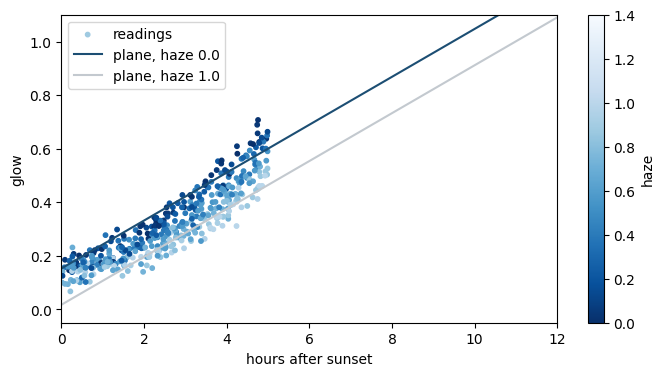

In [4]:
def cost(guess, truth):
    return 0.5 * np.mean((guess - truth)**2)

early = hours < 5
x1, t1 = inputs[early], glow[early]

w, b = np.zeros(2), 0.0
for _ in range(2000):                       # train
    r = linear_perceptron(x1, w, b) - t1    # residuals
    w, b = w - 0.5 * x1.T @ r / len(r), b - 0.5 * r.mean()   # gradient descent step, alpha = 0.5
print(w, b, 'parameters')

def draw_plane(guess, label):
    '''Predict along a clear night and a hazy one.'''
    span = np.linspace(0, 12, 100)
    for hz, color in [(0.0, PRUSSIAN), (1.0, CONSTRUCT)]:
        at = np.column_stack([span / 12, np.full(100, hz)])
        plt.plot(span, guess(at), color=color, label=f'{label}, haze {hz}')

draw_glow(early)
draw_plane(lambda x: linear_perceptron(x, w, b), 'plane')
plt.legend();

### Where it fails

The same plane, with the same parameters, now predicts the glow up to
eight hours after sunset. It predicts a glow above 1. The recorded glow
never goes above 1, because the lines cannot shine brighter than full
silver. A plane keeps climbing whatever its parameters, so training on
more readings would not help.

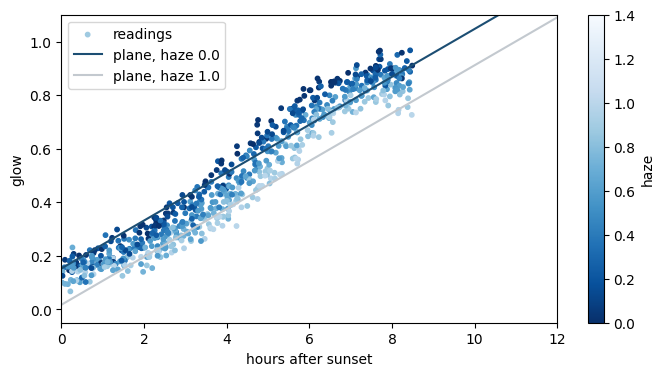

In [5]:
late = hours < 8.5
x2, t2 = inputs[late], glow[late]

draw_glow(late)
draw_plane(lambda x: linear_perceptron(x, w, b), 'plane')   # predict past the hours it was trained on
plt.legend();

### With the activation function

Put $\sigma$ back, so that for reading $i$ the perceptron predicts

$$y_i = \sigma(w \cdot x_i + b)$$

The sigmoid $\sigma(z) = 1/(1 + e^{-z})$ is drawn below. For large
negative $z$ it is close to 0, for large positive $z$ it is close to 1,
and at $z = 0$ it is exactly $\tfrac12$. In between it rises smoothly.
Whatever the sum $w \cdot x_i + b$ comes to, the prediction lies
between 0 and 1. The dashed line is the slope of the sigmoid, which
the gradient below needs. It is largest at $z = 0$, where it is
$\tfrac14$, and close to 0 at both ends.

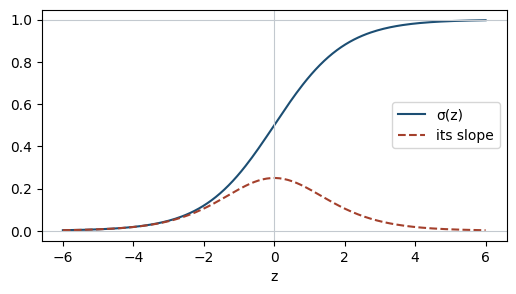

In [6]:
zs = np.linspace(-6, 6, 200)
plt.figure(figsize=(6, 3))
plt.plot(zs, sigmoid(zs), color=PRUSSIAN, label='σ(z)')
plt.plot(zs, sigmoid(zs) * (1 - sigmoid(zs)), '--', color=MADDER, label='its slope')
plt.axhline(0, color=CONSTRUCT, lw=0.8); plt.axhline(1, color=CONSTRUCT, lw=0.8)
plt.axvline(0, color=CONSTRUCT, lw=0.8)
plt.xlabel('z'); plt.legend();

As before, $y_i$ is the predicted glow and $t_i$ is the recorded glow.
The prediction now stays between 0 and 1, as the glow does. The residual
and the cost are unchanged:

$$r_i = y_i - t_i, \qquad C = \frac{1}{2n}\sum_{i=1}^{n} r_i^2$$

What changes is how the cost depends on the parameters, because $y_i$ now
has $\sigma$ in it. Take one weight $w_j$ and follow the chain from $w_j$
to $C$, one link at a time.

1. The sum $w \cdot x_i + b$ changes with $w_j$ at the rate $x_{ij}$,
   because $w_j$ multiplies $x_{ij}$ and nothing else.
2. The prediction $y_i = \sigma(\text{sum})$ changes with the sum at the
   rate of the sigmoid's slope. That slope is $\sigma\,(1 - \sigma)$, and
   at this reading $\sigma(\text{sum})$ is $y_i$, so the rate is
   $y_i\,(1 - y_i)$.
3. The residual $r_i = y_i - t_i$ changes with $y_i$ at the rate $1$,
   because $t_i$ is a fixed number.
4. The cost changes with $r_i$ at the rate $r_i / n$, because
   differentiating $\tfrac{1}{2n} r_i^2$ gives $\tfrac{1}{n} r_i$.

The rates along the chain multiply, and the readings add up:

$$\frac{\partial C}{\partial w_j} = \sum_{i=1}^{n} \frac{r_i}{n}\; y_i\,(1 - y_i)\; x_{ij}$$

The bias is the same chain with the first link changed: the sum changes
with $b$ at the rate $1$, so

$$\frac{\partial C}{\partial b} = \sum_{i=1}^{n} \frac{r_i}{n}\; y_i\,(1 - y_i)$$

Compared with the plane, the only new factor is $y_i\,(1 - y_i)$, the
slope of the sigmoid at each reading. The code computes
$r_i\,y_i\,(1 - y_i) / n$ once per reading, as `factor`, and the slope in
$w$ is the matrix product $X^{\mathsf T}$ times that vector.

Trained on the readings up to eight hours, the perceptron levels off
where the plane kept climbing.

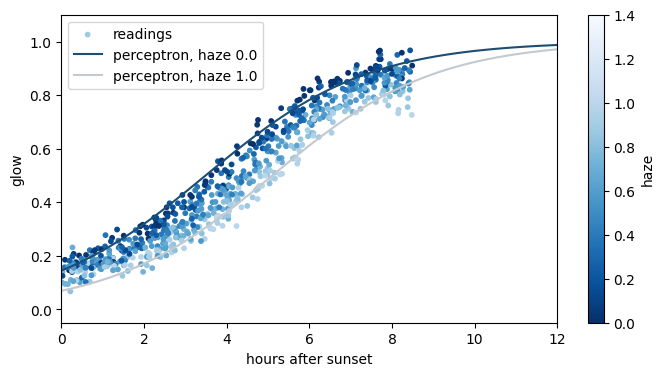

In [7]:
def train_perceptron(x, truth, steps=5000, alpha=3.0):
    w, b = np.zeros(2), 0.0
    for _ in range(steps):                  # train
        y = perceptron(x, w, b)
        factor = (y - truth) * y * (1 - y) / len(truth)   # r_i y_i (1 - y_i) / n, one per reading
        w, b = w - alpha * x.T @ factor, b - alpha * factor.sum()   # gradient descent step
    return w, b

w, b = train_perceptron(x2, t2)
draw_glow(late)
draw_plane(lambda x: perceptron(x, w, b), 'perceptron')
plt.legend();

## II. Multiple layers

A function that bends twice is made from two perceptrons that bend once
each. Put two perceptrons side by side, reading the same inputs, and feed
their outputs to one more perceptron that weighs them together. The two
side by side are a *hidden layer*: their outputs $h$ are never read
directly, only through the perceptron on top, the *output layer*.

![A hidden layer of two units, and the output layer](network.svg)

Each layer has its own weights and bias, numbered by layer:

$$h = \sigma\bigl(x\,W^{(1)} + b^{(1)}\bigr), \qquad
y = h \cdot w^{(2)} + b^{(2)}$$

$W^{(1)}$ has one column of weights per hidden unit and $b^{(1)}$ one
entry per hidden unit, so that the two units are computed at once.
$w^{(2)}$ and $b^{(2)}$ are the output layer's weights and bias. The
output layer has no $\sigma$ when the answer is a number rather than a
yes or no.

### The gradient, by the chain rule

The cost is the same as for the single perceptron, with $y_i$ now the
output of the output layer:

$$h_{ik} = \sigma\bigl(x_i \cdot W^{(1)}_{\cdot k} + b^{(1)}_k\bigr), \qquad
y_i = \sum_k h_{ik}\, w^{(2)}_k + b^{(2)}, \qquad
r_i = y_i - t_i, \qquad
C = \frac{1}{2n}\sum_{i=1}^{n} r_i^2$$

Here $i$ numbers the readings, $k$ the hidden units and $j$ the inputs,
and $W^{(1)}_{\cdot k}$ is the column of weights of hidden unit $k$. The
slopes are found by following the chain from each parameter to the cost,
as before, starting at the cost and working back.

1. The cost changes with $y_i$ at the rate $r_i / n$, exactly as for the
   single perceptron.
2. The output layer is a perceptron without a sigmoid, whose inputs are
   the $h_{ik}$. So its slopes are those of the plane in section I, with
   $h$ in place of $x$:

   $$\frac{\partial C}{\partial w^{(2)}_k} = \sum_{i=1}^{n} \frac{r_i}{n}\, h_{ik}, \qquad
   \frac{\partial C}{\partial b^{(2)}} = \sum_{i=1}^{n} \frac{r_i}{n}$$

3. One step further back, $y_i$ changes with $h_{ik}$ at the rate
   $w^{(2)}_k$, because $w^{(2)}_k$ multiplies $h_{ik}$ and nothing else.
   So the cost changes with $h_{ik}$ at the rate

   $$\frac{\partial C}{\partial h_{ik}} = \frac{r_i}{n}\, w^{(2)}_k$$

4. Each hidden unit is a perceptron with a sigmoid, and its slopes are
   those of the perceptron with the activation function in section I,
   with $\partial C / \partial h_{ik}$ in place of $r_i / n$:

   $$\frac{\partial C}{\partial W^{(1)}_{jk}} = \sum_{i=1}^{n} \frac{\partial C}{\partial h_{ik}}\, h_{ik}(1 - h_{ik})\, x_{ij}, \qquad
   \frac{\partial C}{\partial b^{(1)}_k} = \sum_{i=1}^{n} \frac{\partial C}{\partial h_{ik}}\, h_{ik}(1 - h_{ik})$$

Steps 2 and 3 use step 1, and step 4 uses step 3. In the code each step
is one line, and the sums over $i$ are matrix products. A difference
quotient on one weight checks the result against the apprentice's
readings.

In [8]:
def forward(params, x):
    W1, b1, w2, b2 = params
    h = sigmoid(x @ W1 + b1)
    return h, h @ w2 + b2

def backward(params, x, h, r):
    '''r holds r_i / n, one per reading.'''
    W1, b1, w2, b2 = params
    dw2, db2 = h.T @ r, r.sum()          # step 2
    dh = np.outer(r, w2)                 # step 3
    through = dh * h * (1 - h)           # step 4, through the sigmoid
    dW1, db1 = x.T @ through, through.sum(0)
    return [dW1, db1, dw2, db2]

def glow_grad(params):
    h, y = forward(params, inputs)
    return backward(params, inputs, h, (y - glow) / len(glow))

def random_weights(inputs_in: int, hidden: int, rng):
    return [rng.normal(0, 1, (inputs_in, hidden)), np.zeros(hidden),
            rng.normal(0, 1, hidden), np.float64(0)]

params = random_weights(2, 2, np.random.default_rng(0))
bump = np.zeros((2, 2)); bump[0, 0] = 1e-6
before = cost(forward(params, inputs)[1], glow)
after_bump = cost(forward([params[0] + bump] + params[1:], inputs)[1], glow)
print((after_bump - before) / 1e-6, glow_grad(params)[0][0, 0])

0.04264379735441359 0.04264379734288958


### Problem I, the whole night

Over the whole night the glow rises and
then falls as the moon sets. A sigmoid only rises, or only falls, and one
perceptron has one sigmoid: trained on the whole dataset it settles for a
slope through the middle.

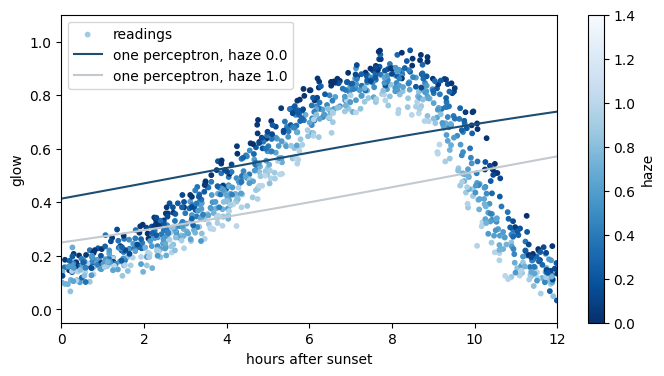

In [9]:
w, b = train_perceptron(inputs, glow)       # train on the whole night
draw_glow()
draw_plane(lambda x: perceptron(x, w, b), 'one perceptron')
plt.legend();

### Training the two layers

Gradient descent on all four arrays at once, from random parameters, with
a fixed step length. The stepper is written as a generator that yields
where it stands, and `after` runs it a number of steps. The trained curve
follows the readings on clear nights and on hazy ones.

0.0010727673555737706 cost trained


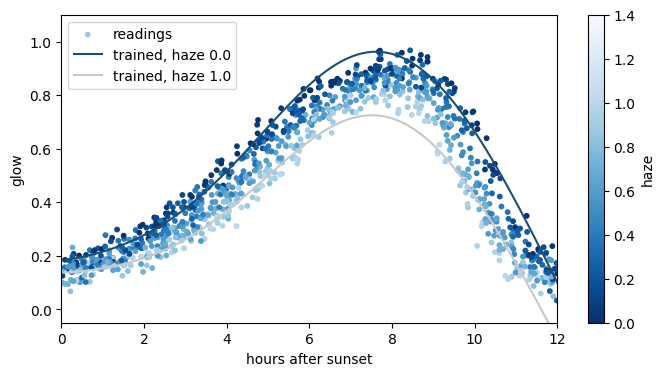

In [10]:
def gradient_descent(params, grad, alpha):
    while True:
        yield params
        params = [p - alpha * g for p, g in zip(params, grad(params))]

def after(steps, path):
    return next(islice(path, steps, None))

two_units = after(30000, gradient_descent(random_weights(2, 2, np.random.default_rng(0)),
                                         glow_grad, alpha=0.3))   # train
print(cost(forward(two_units, inputs)[1], glow), 'cost trained')   # predict on the dataset, and score

draw_glow()
draw_plane(lambda x: forward(two_units, x)[1], 'trained')
plt.legend();

### What each unit computes

Drawn on their own for a clear night, the two
hidden units are two switches, and the output neuron's weights say which
is which: the one weighed positive turns the glow on, the one weighed
negative turns it off. Where the trained prediction crosses one half gives the
hours the letters can be read.

readable from 3.9 to 10.6 hours after sunset


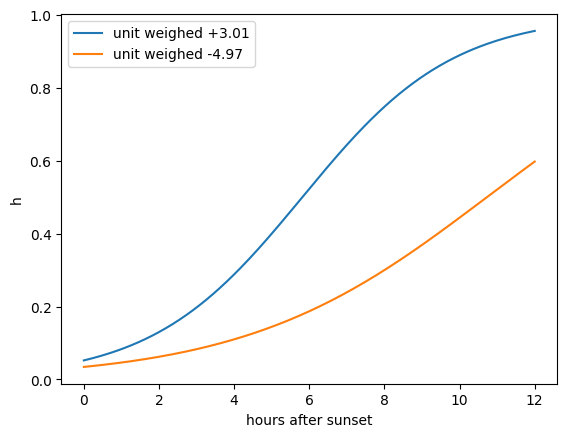

In [11]:
span = np.linspace(0, 12, 200)
clear_night = np.column_stack([span / 12, np.zeros(200)])
h, y = forward(two_units, clear_night)   # predict on a clear night
W1, b1, w2, b2 = two_units
for unit in np.argsort(-w2):
    plt.plot(span, h[:, unit], label=f'unit weighed {w2[unit]:+.2f}')
plt.xlabel('hours after sunset'); plt.ylabel('h'); plt.legend()

shining = span[y > 0.5]
print(f'readable from {shining[0]:.1f} to {shining[-1]:.1f} hours after sunset')

## III. The decision boundary

With two inputs and a yes or no for an output, the set of inputs where the
network changes its answer is a curve across the map, the *decision
boundary*. Each hidden unit contributes one straight line to it, and the
output layer decides which side of which lines counts as yes.

The data: on the night at the doors, clouds crossed the moon and lit the
wall a patch at a time. Wherever a patch fell, the hobbits noted silver or
stone at each spot. Is a given spot on the door silver?

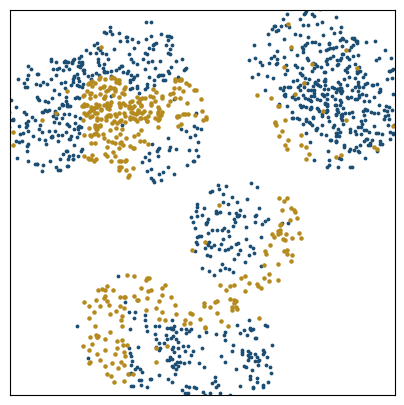

In [12]:
door = np.loadtxt('data/door.csv', delimiter=',', skiprows=1)
points, silver = door[:, :2], door[:, 2]

side = np.linspace(-1, 1, 200)
gx, gy = np.meshgrid(side, side)
frame = np.column_stack([gx.ravel(), gy.ravel()])

def draw_door(output=None, lines=None):
    if output is not None:
        plt.pcolormesh(gx, gy, output.reshape(gx.shape), cmap='gray', vmin=0, vmax=1)
    if lines is not None:
        W, b = lines
        for unit in range(W.shape[1]):
            edge = (frame @ W[:, unit] + b[unit]).reshape(gx.shape)
            plt.contour(gx, gy, edge, levels=[0], colors=MADDER, linewidths=0.8)
    stone = silver == 0
    plt.scatter(*points[stone].T, s=3, color=PRUSSIAN)
    plt.scatter(*points[~stone].T, s=5, color=OCHRE)
    plt.axis((-1, 1, -1, 1)); plt.gca().set_aspect('equal')
    plt.xticks([]); plt.yticks([])

plt.figure(figsize=(5, 5))
draw_door()

### Cross-entropy

Pass the output through the sigmoid as well, so that $p = \sigma(\cdot)$
lies between 0 and 1 and reads as the network's output for "silver". For
a yes or no the cost is *cross-entropy*: $-\log p$ where the truth is 1
and $-\log(1-p)$ where it is 0, so that a wrong answer given with $p$ near
0 or 1 costs a great deal.

$$C = -\tfrac1n \textstyle\sum_i \bigl(y_i \log p_i + (1 - y_i)\log(1 - p_i)\bigr)$$

Its slope through the output sigmoid collapses to $p - y$: the same residual
as before, so `backward` is reused unchanged. The whole set of points goes
through as one matrix, a row per point, which is called a *batch*. The
stepper from here on is Adam, the one from the previous notebook, used as
it stands because it is quicker.

In [13]:
def classify(params, x):
    h, z = forward(params, x)
    return h, sigmoid(z)

def cross_entropy(p, truth):
    p = np.clip(p, 1e-12, 1 - 1e-12)  # a saturated sigmoid would give log 0
    return -np.mean(truth * np.log(p) + (1 - truth) * np.log(1 - p))

def door_grad(params):
    h, p = classify(params, points)
    return backward(params, points, h, (p - silver) / len(points))

def adam(params, grad, alpha, b1=0.9, b2=0.999):
    m = [np.zeros_like(p) for p in params]
    s = [np.zeros_like(p) for p in params]
    for k in count(1):
        yield params
        g = grad(params)
        m = [b1 * mi + (1 - b1) * gi for mi, gi in zip(m, g)]
        s = [b2 * si + (1 - b2) * gi**2 for si, gi in zip(s, g)]
        params = [p - alpha * (mi / (1 - b1**k)) / (np.sqrt(si / (1 - b2**k)) + 1e-8)
                  for p, mi, si in zip(params, m, s)]

def fit_door(hidden, steps=3000, alpha=0.03, seed=0):
    '''Train on every noted point at once.'''
    path = adam(random_weights(2, hidden, np.random.default_rng(seed)), door_grad, alpha)
    return after(steps, path)

def show_door(params, model=classify):
    '''Predict at the noted points, to score, and over the whole frame, to draw.'''
    _, p = model(params, points)
    _, output = model(params, frame)
    draw_door(output, params[:2])
    plt.title(f'{params[0].shape[1]} units, {np.mean((p > 0.5) == silver):.0%} right')

### One unit

A single unit splits the door along the straight line
$x \cdot w + b = 0$, where its output crosses one half: silver on one side,
stone on the other. The best such line is drawn in red. It is wrong in
plain sight, and only a little better than calling every spot stone.

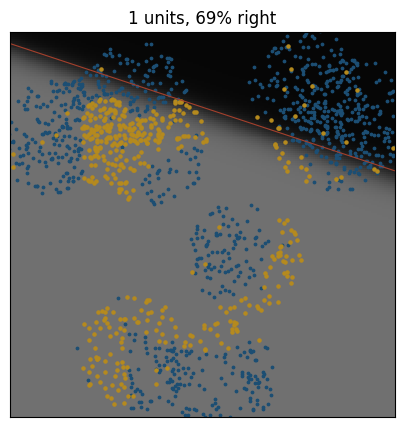

In [14]:
plt.figure(figsize=(5, 5))
show_door(fit_door(1))

### Two units

Two lines, weighed with opposite signs by the top layer,
make a band: the bump of the hidden layer, across a map. It lands on the
stem of the letter, with one line along each edge.

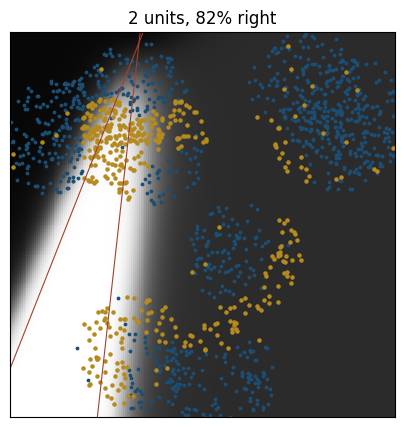

In [15]:
plt.figure(figsize=(5, 5))
show_door(fit_door(2))

### More units

Every hidden unit is one straight line, and the top layer
adds up which side of each a point lies on. A curve takes many lines. With
four and eight the bow is a few straight pieces; by sixteen it closes, and
at thirty-two the edge is smooth and the lines too many to read one by
one.

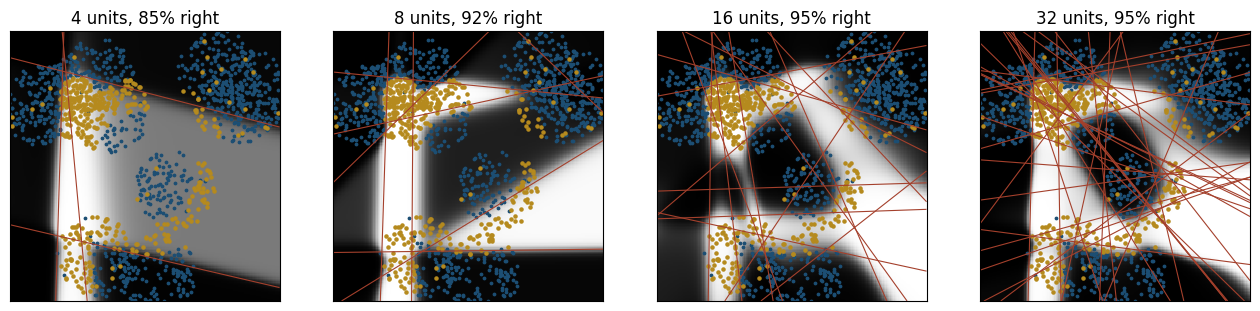

In [16]:
plt.figure(figsize=(16, 4))
for i, hidden in enumerate([4, 8, 16, 32]):
    plt.subplot(1, 4, i + 1)
    show_door(fit_door(hidden))

### Watching it train

Sixteen units from a random start, drawn after 0,
30, 100, 300, 1000 and 3000 steps. The lines begin anywhere, and move to
where the mistakes are.

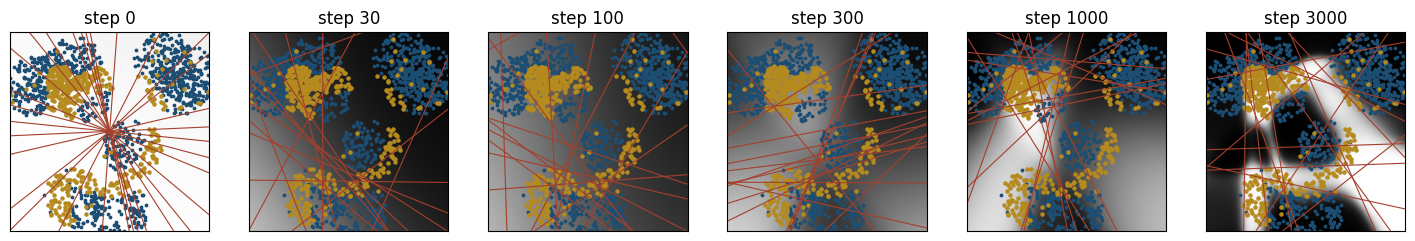

In [17]:
path = adam(random_weights(2, 16, np.random.default_rng(0)), door_grad, alpha=0.03)
snapshots = [0, 30, 100, 300, 1000, 3000]
plt.figure(figsize=(18, 3.3))
for step, params in zip(range(snapshots[-1] + 1), path):
    if step in snapshots:
        plt.subplot(1, 6, snapshots.index(step) + 1)
        show_door(params)
        plt.title(f'step {step}')

### Breaking it: every parameter at zero

All sixteen units start identical and
receive identical slopes, so they stay identical for ever: one unit wearing
sixteen hats, and the result is the one-unit split from before. In the very
first step not even that moves, since with $w^{(2)} = 0$ the slope of
the cost in the first layer is exactly zero. Random starting parameters exist to break this
tie.

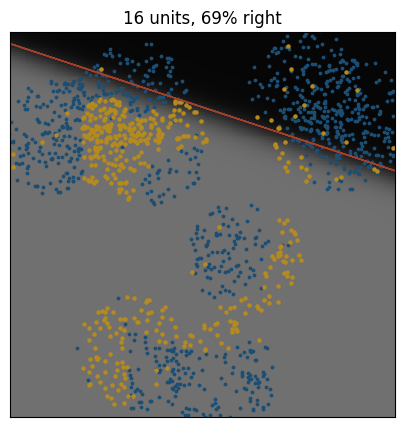

In [18]:
zeros = [np.zeros((2, 16)), np.zeros(16), np.zeros(16), np.float64(0)]
plt.figure(figsize=(5, 5))
show_door(after(3000, adam(zeros, door_grad, alpha=0.03)))

### Breaking it: too long a step

The same sixteen units, with plain
gradient descent at step lengths 1, 10 and 100. The first crawls, the
second descends, and the third throws the parameters past the bottom every
step, so the cost climbs instead of falling.

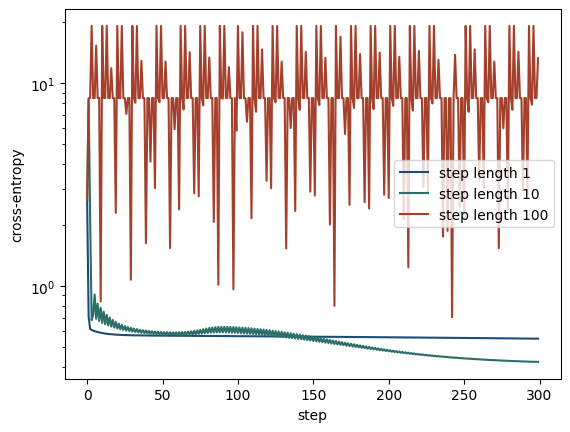

In [19]:
for alpha, color in [(1, PRUSSIAN), (10, VERDIGRIS), (100, MADDER)]:
    path = gradient_descent(random_weights(2, 16, np.random.default_rng(0)), door_grad, alpha)
    costs = [cross_entropy(classify(p, points)[1], silver) for p in islice(path, 300)]
    plt.plot(costs, color=color, label=f'step length {alpha}')
plt.yscale('log'); plt.xlabel('step'); plt.ylabel('cross-entropy'); plt.legend();

### Breaking it: no sigmoid

Take the sigmoid out from between the layers,
so that $h = X W^{(1)} + b^{(1)}$ and the output is
$\sigma\bigl(X W^{(1)} w^{(2)} + b^{(1)} w^{(2)} + b^{(2)}\bigr)$. That is one
affine map followed by one sigmoid, however many units there are: a
composition of affine maps is affine. Thirty-two units draw a single
straight line. The sigmoid between the layers is the whole reason a hidden
layer can do more than one neuron.

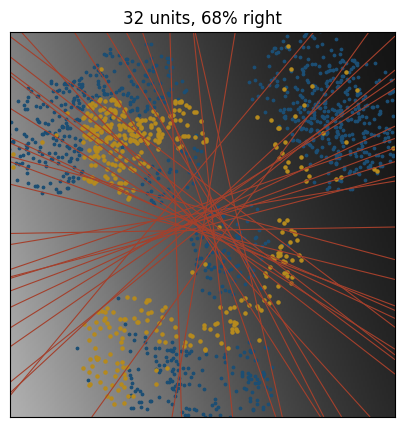

In [20]:
def classify_plain(params, x):
    W1, b1, w2, b2 = params
    h = x @ W1 + b1
    return h, sigmoid(h @ w2 + b2)

def plain_grad(params):
    W1, b1, w2, b2 = params
    h, p = classify_plain(params, points)
    r = (p - silver) / len(points)
    dh = np.outer(r, w2)   # no sigmoid, so no h(1 - h)
    return [points.T @ dh, dh.sum(0), h.T @ r, r.sum()]

plt.figure(figsize=(5, 5))
plain = after(3000, adam(random_weights(2, 32, np.random.default_rng(0)), plain_grad, 0.03))
show_door(plain, classify_plain)

## IV. Several layers

With a picture for input, a hidden unit's weights are themselves a
picture, and a layer of them is a set of patterns to match. A second
layer matches patterns of patterns. The forward and backward passes
become loops over a list of layers, and the output becomes one answer
out of several.

The data: twelve Elvish letters, drawn clean below, each with the sound
it stands for on the doors. Each is cut out as a 16 by 16 picture, so a
letter is 256 numbers in and one of twelve answers out. One set of
pictures has the letters centred; one has them left where they fell,
shifted and turned a little, as a chisel drifts.

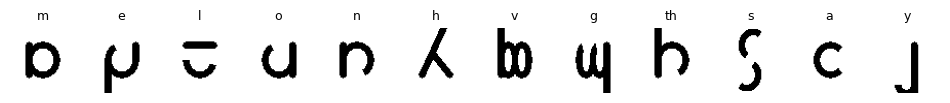

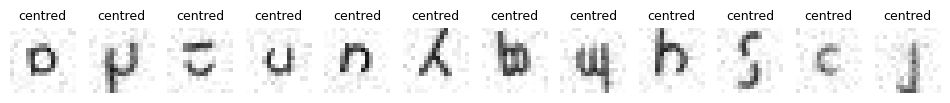

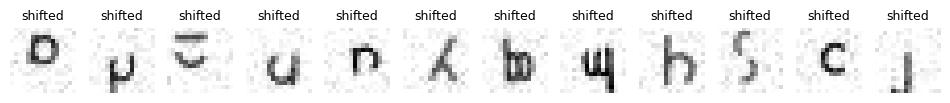

In [21]:
glyphs = np.load('data/tengwar.npz')
names = list(glyphs['names'])

def flat(images):
    return images.reshape(len(images), -1) / 255

def load(kind):
    return (flat(glyphs[f'{kind}_train_images']), glyphs[f'{kind}_train_labels'],
            flat(glyphs[f'{kind}_val_images']), glyphs[f'{kind}_val_labels'])

still_x, still_y, still_vx, still_vy = load('still')
moved_x, moved_y, moved_vx, moved_vy = load('moved')
classes = still_y.max() + 1

def show_grid(images, titles, columns=12):
    rows = -(-len(images) // columns)
    plt.figure(figsize=(columns, 1.3 * rows))
    for i, (image, title) in enumerate(zip(images, titles)):
        side = int(np.sqrt(image.size))
        plt.subplot(rows, columns, i + 1)
        plt.imshow(image.reshape(side, side), cmap='gray_r', vmin=0, vmax=1)
        plt.title(title, fontsize=9); plt.axis('off')

show_grid(glyphs['clean_images'], names[:classes])
first = [np.flatnonzero(still_y == k)[0] for k in range(classes)]
show_grid(still_x[first], ['centred'] * classes)
first = [np.flatnonzero(moved_y == k)[0] for k in range(classes)]
show_grid(moved_x[first], ['shifted'] * classes)

### Softmax

The last layer has twelve neurons, one score $z_k$ per letter.
The *softmax* turns the twelve scores into twelve positive numbers that
sum to one, so that they can be read as the network's shares of belief
over the letters:

$$p_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$$

The exponential makes every share positive and lets the biggest score
dominate; the division makes the shares sum to one. Adding the same
number to every score changes nothing, which is what the code uses to
keep the exponentials from overflowing.

In [22]:
def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

scores = np.array([[2.0, 0.5, -1.0]])
print(softmax(scores).round(3), softmax(scores).sum())
print(softmax(scores + 10).round(3), 'the same, shifted')

[[0.786 0.175 0.039]] 1.0
[[0.786 0.175 0.039]] the same, shifted


### Cross-entropy for several answers

It charges $-\log$ of the share given
to the right letter, averaged over the pictures:

$$C = -\tfrac1n \sum_i \log p_{i,\,y_i}$$

Its slope at the scores is $p$ with 1 subtracted at the right letter,
divided by $n$: output minus truth, once more. Why softmax and
cross-entropy are the right pair rests on probability, which is not
covered here.

### A list of layers

`forward_layers` applies affine map then sigmoid
for every layer but the last, and softmax on the last. `backward_layers`
hands the residual back one layer at a time, collecting a slope for each
$W$ and $b$: the `backward` of the hidden layer, in a loop.

In [23]:
def forward_layers(layers, x):
    activations = [x]
    for W, b in layers[:-1]:
        activations.append(sigmoid(activations[-1] @ W + b))
    W, b = layers[-1]
    activations.append(softmax(activations[-1] @ W + b))
    return activations

def backward_layers(layers, x, labels):
    activations = forward_layers(layers, x)
    delta = activations[-1].copy()
    delta[np.arange(len(x)), labels] -= 1
    delta /= len(x)
    slopes = []
    for (W, b), h in zip(reversed(layers), reversed(activations[:-1])):
        slopes.append((h.T @ delta, delta.sum(0)))
        delta = (delta @ W.T) * h * (1 - h)
    return slopes[::-1]

def new(sizes, rng):
    return [(rng.normal(0, 1 / np.sqrt(m), (m, n)), np.zeros(n))
            for m, n in zip(sizes, sizes[1:])]

def accuracy(layers, x, labels):
    '''Predict every picture and count the right answers.'''
    return np.mean(forward_layers(layers, x)[-1].argmax(axis=1) == labels)

def loss(layers, x, labels):
    p = forward_layers(layers, x)[-1]
    return -np.mean(np.log(p[np.arange(len(x)), labels]))

### Handfuls

A slope over all the training pictures costs a forward and
a backward pass for each of them. A slope over 64 pictures drawn at random
costs 64 and, on average, points the same way; that is stochastic gradient
descent, and each Adam step here draws its own handful. The layers are
flattened into one list of parameters so the same stepper serves. One pass over
the data in handfuls is an *epoch*.

In [24]:
BATCH = 64

def pairs(flat_params):
    return list(zip(flat_params[::2], flat_params[1::2]))

def train(layers, x, labels, epochs, rng, alpha=0.003):
    '''Train: each Adam step on a fresh handful of pictures.'''
    def grad(flat_params):
        handful = rng.integers(0, len(x), BATCH)
        slopes = backward_layers(pairs(flat_params), x[handful], labels[handful])
        return [g for layer in slopes for g in layer]
    flat_params = [p for layer in layers for p in layer]
    return pairs(after(epochs * len(x) // BATCH, adam(flat_params, grad, alpha)))

rng = np.random.default_rng(3)
one_still = train(new([256, classes], rng), still_x, still_y, 20, rng)
print(f'one layer, centred letters: {accuracy(one_still, still_vx, still_vy):.1%} right')

one layer, centred letters: 100.0% right


### One layer is twelve templates

With no hidden layer the network is
twelve neurons, each reading 256 pixels. Each neuron's weights are
themselves a 16 by 16 picture, and drawn as one they are the letters: a
score is high where the picture's ink lands on the template's ink.
Centred letters land on the template every time, so the validation set is
read without error.

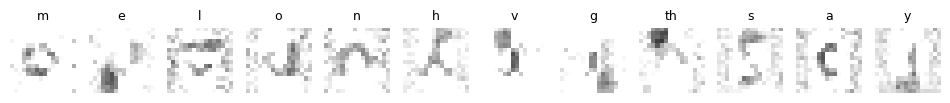

In [25]:
show_grid(one_still[0][0].T, names[:classes])

### Shifted letters need a hidden layer

On the pictures left where they
fell, a template matches a stroke only where the stroke happens to land.
The weights smear out and about one letter in eight is misread. With 128 hidden
units between, each watching for a piece of stroke the way a unit in the
decision boundary watched one side of a line, the top layer reads letters
off those pieces instead of off pixels.

one layer, shifted letters: 87.9% right
two layers, shifted letters: 98.9% right


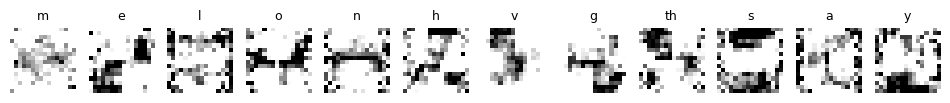

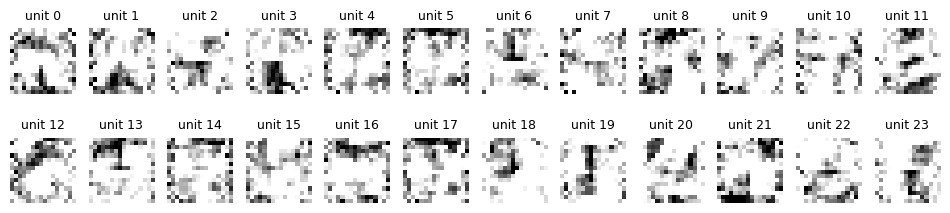

In [26]:
one_moved = train(new([256, classes], rng), moved_x, moved_y, 60, rng)
two_moved = train(new([256, 128, classes], rng), moved_x, moved_y, 60, rng)
for name, net in [('one layer', one_moved), ('two layers', two_moved)]:
    print(f'{name}, shifted letters: {accuracy(net, moved_vx, moved_vy):.1%} right')

show_grid(one_moved[0][0].T, names[:classes])
show_grid(two_moved[0][0].T[:24], [f'unit {i}' for i in range(24)])

### What it still misreads

The validation pictures the two-layer network
gets wrong, labelled with its answer and the truth.

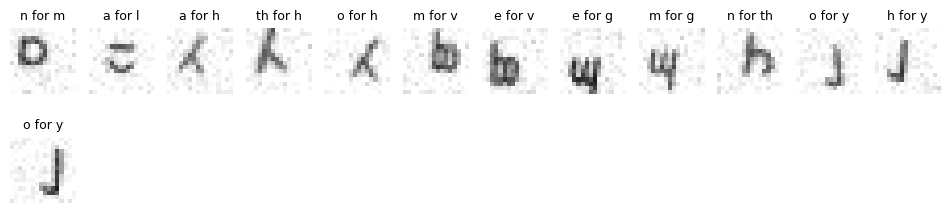

In [27]:
read = forward_layers(two_moved, moved_vx)[-1].argmax(axis=1)  # predict
wrong = np.flatnonzero(read != moved_vy)[:24]
show_grid(moved_vx[wrong], [f'{names[g]} for {names[t]}' for g, t in zip(read[wrong], moved_vy[wrong])])

### Overfitting

Train the same two layers on only twenty pictures per
letter, for eighty epochs, and record the cost on those pictures and on
the validation set after each epoch. The training cost keeps falling,
because 34,000 parameters can learn 240 pictures by heart. The validation cost
turns and climbs. Only data the network never trained on says how well it
reads.

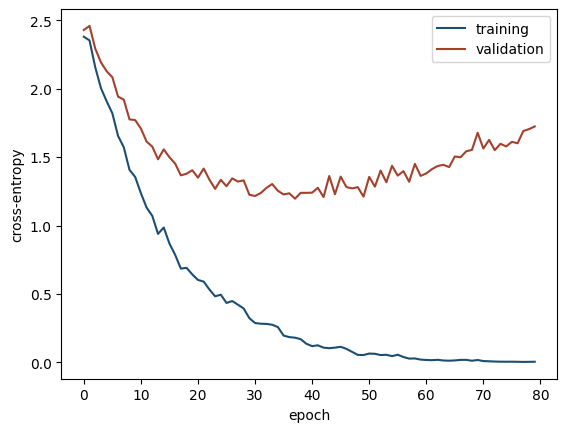

In [28]:
few = np.concatenate([np.flatnonzero(moved_y == k)[:20] for k in range(classes)])
few_x, few_y = moved_x[few], moved_y[few]
small = new([256, 128, classes], rng)
curves = []
for epoch in range(80):
    small = train(small, few_x, few_y, 1, rng, alpha=0.01)
    curves.append((loss(small, few_x, few_y), loss(small, moved_vx, moved_vy)))

training, validation = np.array(curves).T
plt.plot(training, color=PRUSSIAN, label='training')
plt.plot(validation, color=MADDER, label='validation')
plt.xlabel('epoch'); plt.ylabel('cross-entropy'); plt.legend();

### The word on the door

Six letters, read one at a time by the
two-layer network and printed as the sounds they stand for.

mellon


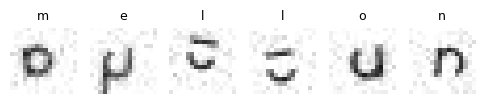

In [29]:
word_x = flat(glyphs['word_images'])
read = forward_layers(two_moved, word_x)[-1].argmax(axis=1)  # predict
show_grid(word_x, [names[k] for k in read], columns=6)
print(''.join(names[k] for k in read))

### What it cannot do

A thirteenth letter, rómen, was never in the
training pictures. The network has twelve outputs and no way to say "none
of these", so it names one of its twelve with a large share. A letter
drawn at twice the size does not fit the 16 by 16 window its templates
were learned in, and gets the same treatment.

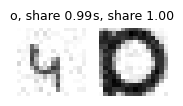

In [30]:
strangers = flat(np.stack([glyphs['unseen_image'], glyphs['giant_image']]))
outputs = forward_layers(two_moved, strangers)[-1]  # predict
show_grid(strangers, [f'{names[o.argmax()]}, share {o.max():.2f}' for o in outputs], columns=3)